# Decode & Detect: LightGBM detector

This notebook trains a gradient-boosted tree detector:

1. Load the payments.
2. Turn each payment into a few **features**: simple rules such as "the receiver sends the money on within an hour".
3. Train a **LightGBM** model on the labelled `train/` data. Unlike a logistic regression, which adds the rules up, it learns **combinations** of rules, such as "fast *and* passes almost everything on".
4. Score the test data and write `predictions_lightgbm.csv`, ready to upload at https://hackathon.ukcbt.org.

To improve your score, add your own rules in step 2 and run the notebook again.

**Setup:** put this notebook next to the `train/` folder and `payments.py` from the training download, and unzip the test download into a folder called `test-data/`. Then install the libraries:

```sh
pip install pandas pyarrow scikit-learn lightgbm jupyter
```

On macOS LightGBM also needs the OpenMP runtime: `brew install libomp`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

from payments import load_payments

TRAIN_DIR = Path("train")
TEST_DIR = Path("test-data")  # where you unzipped the test download

## 1. Load the payments

`load_payments` (from the download) gives one row per transaction: who sent it (`FROM_ADDRESS`), who received it (`TO_ADDRESS`), when (`TIMESTAMP`, in seconds) and its value in US dollars (`VALUE`), using the hourly reference prices.

In [2]:
def load(directory):
    return pd.DataFrame(load_payments(directory))


train = load(TRAIN_DIR)
labels = pd.read_csv(TRAIN_DIR / "labels.csv", usecols=["TRANSACTION_HASH", "is_suspicious"])
train = train.merge(labels, on="TRANSACTION_HASH")
print(f"{len(train):,} training payments, {train.is_suspicious.sum():,} suspicious")
train.head()

40,131 training payments, 1,250 suspicious


,TRANSACTION_HASH,TIMESTAMP,TRANSACTION_INDEX,FROM_ADDRESS,TO_ADDRESS,SOURCE_VALUE,VALUE,TOKEN_ADDRESS,SYMBOL,is_suspicious
0,954736A6E1BB5A3433EB916D8221F2DF5938A521EA2222...,1788718916,0,r3CWFt1SXiykW92LwKU19CvfTFcFRnbnDY,rMWFzNYApzeKVcHyXGSUz2XQpuHmSA11kU,7.624983e+08,762.498271,reference-valuation,USD,0
1,C93CF387C2148608329ED89420105EFD883020CDBFDFAE...,1788766300,1,rEFG2WG1W8bHQhHp2P1rcxRBMxmz9C52B7,rDwLP5NUvC25gwBDHgv5qP9nCZjT8kuZSy,3.170385e+08,317.038538,reference-valuation,USD,0
2,E46BFC5EC409B486E1C97F20BCB62AE96432B20937D265...,1788737068,1,rJxqpGRZ2bJtB1Q8HYCV9iPon9HpvJugZm,rsSAFra1UVoobuNrQzh7HJHepjvSTkHyAM,1.885882e+06,1.885882,reference-valuation,USD,0
3,E7CAB61BBDAC502147EF393C7EA93A2A937DA3F01623E2...,1788574820,0,rnEiuUDCbbsMqipLBQvUvkQyjhcM1vDtHB,rP5qUwE6qmTDzME7kqjP4CGAb8v9x17QE6,1.242573e+07,12.425732,reference-valuation,USD,0
4,E9549020D2717DB401CA4C30BB82500758ABF100600D9C...,1788707968,2,rwWTLZeD4QEMAiJ4QsmVgeWDJj6NMrw4Bx,rGkwo8Zrgj3hMT61iswFgnxGTs3ALKEgCU,1.063581e+08,106.358082,reference-valuation,USD,0


## 2. Features: simple rules

Each feature is one simple idea about suspicious money movement. The model only sees these numbers, so **this is where your ideas go**.

In [3]:
HOUR, TEN_MINUTES = 3600, 600


def count_in_window(times_by_account, account, t, before, after):
    """How many of an account's payments fall between t - before and t + after."""
    times = times_by_account.get(account)
    if times is None:
        return 0
    return int(np.searchsorted(times, t + after, "right") - np.searchsorted(times, t - before, "left"))


def make_features(df):
    df = df.sort_values("TIMESTAMP").reset_index(drop=True)
    t = df.TIMESTAMP.astype(int).to_numpy()
    value = df.VALUE.to_numpy()
    sends = {a: g.TIMESTAMP.astype(int).to_numpy() for a, g in df.groupby("FROM_ADDRESS")}
    gets = {a: g.TIMESTAMP.astype(int).to_numpy() for a, g in df.groupby("TO_ADDRESS")}

    f = pd.DataFrame({"TRANSACTION_HASH": df.TRANSACTION_HASH})

    # Rule: bigger payments are more interesting (log keeps huge ones in range).
    f["log_value"] = np.log1p(value)

    # Rule: how busy are the sender and the receiver over the whole week?
    f["sender_payments"] = df.FROM_ADDRESS.map(df.FROM_ADDRESS.value_counts())
    f["receiver_payments"] = df.TO_ADDRESS.map(df.TO_ADDRESS.value_counts())

    # Rule: the receiver sends money on within an hour (a "relay" or "mule").
    f["receiver_forwards_1h"] = [
        count_in_window(sends, a, ti, 0, HOUR) > 0 for a, ti in zip(df.TO_ADDRESS, t)
    ]

    # Rule: the sender only just received money (it is passing it along).
    f["sender_received_1h_before"] = [
        count_in_window(gets, a, ti, HOUR, 0) > 0 for a, ti in zip(df.FROM_ADDRESS, t)
    ]

    # Rule: fan-out / fan-in, many payments from one sender or into one
    # receiver within ten minutes.
    f["sender_burst_10m"] = [
        count_in_window(sends, a, ti, TEN_MINUTES, TEN_MINUTES) for a, ti in zip(df.FROM_ADDRESS, t)
    ]
    f["receiver_burst_10m"] = [
        count_in_window(gets, a, ti, TEN_MINUTES, TEN_MINUTES) for a, ti in zip(df.TO_ADDRESS, t)
    ]

    # Rule: the receiver passes on a similar amount (within 10%) within an hour,
    # a classic sign of money being layered through an account.
    sent_values = {a: g.VALUE.to_numpy() for a, g in df.groupby("FROM_ADDRESS")}

    def forwards_similar(account, ti, amount):
        times = sends.get(account)
        if times is None:
            return False
        lo, hi = np.searchsorted(times, ti, "right"), np.searchsorted(times, ti + HOUR, "right")
        later = sent_values[account][lo:hi]
        return bool(np.any(np.abs(later - amount) <= 0.1 * amount))

    f["receiver_forwards_similar_1h"] = [
        forwards_similar(a, ti, v) for a, ti, v in zip(df.TO_ADDRESS, t, value)
    ]

    # Rule: the sender received a similar amount within the hour before.
    got_values = {a: g.VALUE.to_numpy() for a, g in df.groupby("TO_ADDRESS")}

    def received_similar(account, ti, amount):
        times = gets.get(account)
        if times is None:
            return False
        lo, hi = np.searchsorted(times, ti - HOUR, "left"), np.searchsorted(times, ti, "left")
        earlier = got_values[account][lo:hi]
        return bool(np.any(np.abs(earlier - amount) <= 0.1 * amount))

    f["sender_received_similar_1h"] = [
        received_similar(a, ti, v) for a, ti, v in zip(df.FROM_ADDRESS, t, value)
    ]

    # Rule: how quickly does the receiver send money on? (minutes, capped at 60)
    def minutes_to_next_send(account, ti):
        times = sends.get(account)
        if times is None:
            return 60.0
        i = np.searchsorted(times, ti, "right")
        return min(60.0, (times[i] - ti) / 60) if i < len(times) else 60.0

    f["receiver_minutes_to_forward"] = [
        minutes_to_next_send(a, ti) for a, ti in zip(df.TO_ADDRESS, t)
    ]

    # Rule: pass-through accounts send on most of what they receive over the week.
    sent_total = df.groupby("FROM_ADDRESS").VALUE.sum()
    got_total = df.groupby("TO_ADDRESS").VALUE.sum()
    pass_through = (sent_total / got_total.reindex(sent_total.index)).clip(0, 3)
    f["sender_pass_through"] = df.FROM_ADDRESS.map(pass_through).fillna(0)
    f["receiver_pass_through"] = df.TO_ADDRESS.map(pass_through).fillna(0)

    # Rule: fast pass-through. What share of this payment does the receiver send on
    # within a few minutes, and what share of it had the sender itself just received?
    # Suspicious "easy" scenarios move money hop to hop about a minute apart and pass on
    # ~96% of it; normal look-alike patterns take ~10 minutes per hop.
    def windowed_sums(account_col):
        """Per account: sorted payment times and running USD totals, for fast window sums."""
        out = {}
        for a, g in df.groupby(account_col):
            order = np.argsort(g.TIMESTAMP.astype(int).to_numpy(), kind="stable")
            times = g.TIMESTAMP.astype(int).to_numpy()[order]
            out[a] = (times, np.concatenate([[0.0], np.cumsum(g.VALUE.to_numpy()[order])]))
        return out

    sent_usd, got_usd = windowed_sums("FROM_ADDRESS"), windowed_sums("TO_ADDRESS")

    def usd_in_window(sums, account, start, end):
        """USD an account sent (or received) with start <= time <= end."""
        if account not in sums:
            return 0.0
        times, cum = sums[account]
        return cum[np.searchsorted(times, end, "right")] - cum[np.searchsorted(times, start, "left")]

    for minutes in (1, 5):
        w = minutes * 60
        # share of this payment the receiver forwards in the next `minutes` (capped at 100%)
        f[f"receiver_forwarded_pct_{minutes}m"] = [
            min(1.0, usd_in_window(sent_usd, a, ti, ti + w) / v) if v > 0 else 0.0
            for a, ti, v in zip(df.TO_ADDRESS, t, value)
        ]
        # share of this payment covered by money the sender received in the previous `minutes`
        f[f"sender_received_pct_{minutes}m"] = [
            min(1.0, usd_in_window(got_usd, a, ti - w, ti) / v) if v > 0 else 0.0
            for a, ti, v in zip(df.FROM_ADDRESS, t, value)
        ]

    # Rule: total money moved around this payment over a scenario-length window.
    # Medium-difficulty suspicious scenarios look like their normal look-alikes in shape,
    # speed and assets, but tend to move somewhat more money in total (about $810 vs $570
    # per scenario; a weak hint, AUC ~0.59). The test data has no scenario IDs, so we
    # approximate "the scenario" as all payments touching this payment's sender or receiver
    # within +/- 1 hour: a 2-hour window, about the median length of a medium scenario (1.8 h).
    SCENARIO_HALF_WINDOW = HOUR

    # Every payment is "activity" for both of its accounts, sending or receiving, so build
    # one time-sorted list per account with running USD totals (sums over any window are
    # then two binary searches instead of a scan).
    touches = pd.concat([
        pd.DataFrame({"account": df.FROM_ADDRESS, "t": t, "usd": value}),
        pd.DataFrame({"account": df.TO_ADDRESS, "t": t, "usd": value}),
    ]).sort_values("t", kind="stable")
    activity_usd = {
        a: (g.t.to_numpy(), np.concatenate([[0.0], np.cumsum(g.usd.to_numpy())]))
        for a, g in touches.groupby("account")
    }
    # Payments directly between the two accounts (either direction) appear in both
    # accounts' lists, so keep them separately per unordered pair to remove the double count.
    pair_key = [frozenset(p) for p in zip(df.FROM_ADDRESS, df.TO_ADDRESS)]
    pair_usd = {
        k: (g.t.to_numpy(), np.concatenate([[0.0], np.cumsum(g.usd.to_numpy())]))
        for k, g in pd.DataFrame({"pair": pair_key, "t": t, "usd": value})
        .sort_values("t", kind="stable").groupby("pair", sort=False)
    }

    def window_usd(sums, key, start, end):
        """USD of the payments in `sums[key]` with start <= time <= end."""
        times, cum = sums[key]
        return cum[np.searchsorted(times, end, "right")] - cum[np.searchsorted(times, start, "left")]

    # Volume = sender's activity + receiver's activity - payments between them (counted
    # twice), all within the window. This payment itself is included exactly once.
    scenario_volume = np.array([
        window_usd(activity_usd, a, ti - SCENARIO_HALF_WINDOW, ti + SCENARIO_HALF_WINDOW)
        + window_usd(activity_usd, b, ti - SCENARIO_HALF_WINDOW, ti + SCENARIO_HALF_WINDOW)
        - window_usd(pair_usd, k, ti - SCENARIO_HALF_WINDOW, ti + SCENARIO_HALF_WINDOW)
        for a, b, k, ti in zip(df.FROM_ADDRESS, df.TO_ADDRESS, pair_key, t)
    ])
    # log keeps a few very large windows from dominating the linear model
    f["scenario_volume_2h"] = np.log1p(scenario_volume)

    # The same volume compared with what these two accounts usually move in 2 hours (their
    # weekly totals spread evenly over the data's time span). All accounts are busy, so
    # "more than usual for these accounts" is a fairer signal than the raw dollar amount.
    weekly_activity = touches.groupby("account").usd.sum()
    windows_in_span = max(1.0, (t.max() - t.min()) / (2 * SCENARIO_HALF_WINDOW))
    usual_volume = (df.FROM_ADDRESS.map(weekly_activity) + df.TO_ADDRESS.map(weekly_activity)) / windows_in_span
    f["scenario_volume_vs_usual"] = np.log1p(scenario_volume / usual_volume.to_numpy())

    return f.astype({c: float for c in f.columns if c != "TRANSACTION_HASH"})


train_features = make_features(train)
y = train.set_index("TRANSACTION_HASH").is_suspicious.loc[train_features.TRANSACTION_HASH].to_numpy()
X = train_features.drop(columns="TRANSACTION_HASH")
X.describe().T[["mean", "max"]]

,mean,max
log_value,4.130822,8.428728
sender_payments,68.592933,216.000000
receiver_payments,75.135606,256.000000
receiver_forwards_1h,0.331365,1.000000
sender_received_1h_before,0.322195,1.000000
sender_burst_10m,1.436869,9.000000
receiver_burst_10m,1.524482,9.000000
receiver_forwards_similar_1h,0.028158,1.000000
sender_received_similar_1h,0.027186,1.000000
receiver_minutes_to_forward,48.790843,60.000000


## 3. Train a LightGBM model and check it

We score held-back training data the same way the site scores you: **100 × average precision**. Higher is better; guessing at random scores about 3.

Two checks:

- **Random 80/20 split**, as in the starter notebook. Tree models look much better here than they really are: payments from the same planted scenario land on both sides of the split, and the model recognises the scenario rather than the pattern.
- **Scenario-grouped 5-fold check**: every payment of a scenario is held back together, so the model is scored on scenarios it has never seen, closer to the test data, which has completely different wallets. **Trust this number.** (The scenario IDs in `labels.csv` are used only to group the check, never as features.)

The model is kept deliberately small (7 leaves per tree, at least 200 payments per leaf, row and column sampling, L2 penalty). Bigger trees score higher on the random split but lower on the grouped check.

In [4]:
def make_model():
    return LGBMClassifier(
        num_leaves=7,            # small trees: few rule combinations per tree
        n_estimators=400,
        learning_rate=0.03,
        min_child_samples=200,   # each leaf must cover many payments, not one scenario
        subsample=0.8, subsample_freq=1,  # each tree sees 80% of payments...
        colsample_bytree=0.8,             # ...and 80% of the rules
        reg_lambda=5,
        random_state=0, deterministic=True, force_col_wise=True, n_jobs=4, verbose=-1,
    )


# Check 1: random 80/20 split (optimistic for tree models, see above)
X_fit, X_check, y_fit, y_check = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
model = make_model().fit(X_fit, y_fit)
check_scores = model.predict_proba(X_check)[:, 1]
print(f"Score on random 80/20 split:            {100 * average_precision_score(y_check, check_scores):.1f}")

# Check 2: hold back whole scenarios at a time (payments outside any scenario are their own group)
scenario = (pd.read_csv(TRAIN_DIR / "labels.csv", usecols=["TRANSACTION_HASH", "scenario_id"])
            .set_index("TRANSACTION_HASH").scenario_id.loc[train_features.TRANSACTION_HASH])
groups = scenario.fillna(pd.Series(scenario.index, index=scenario.index)).to_numpy()
grouped_scores = np.zeros(len(y))
for fit_rows, check_rows in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0).split(X, y, groups):
    grouped_scores[check_rows] = make_model().fit(X.iloc[fit_rows], y[fit_rows]).predict_proba(X.iloc[check_rows])[:, 1]
print(f"Score on scenario-grouped 5-fold check: {100 * average_precision_score(y, grouped_scores):.1f}")

Score on random 80/20 split:            47.8


Score on scenario-grouped 5-fold check: 44.4


### Which rules mattered?

Trees have no weights with a sign, so instead we show each rule's **importance**: how much it improved the model's fit (total gain) across all its splits, as a share of the total. A high share means the model leaned on that rule a lot; it does not say whether the rule makes a payment look more or less suspicious.

In [5]:
importance = pd.Series(model.booster_.feature_importance("gain"), index=X.columns)
(100 * importance / importance.sum()).sort_values(ascending=False).round(1)

sender_burst_10m                17.1
receiver_burst_10m              15.7
receiver_forwarded_pct_5m        9.1
sender_received_pct_5m           8.3
receiver_payments                8.3
receiver_minutes_to_forward      7.0
log_value                        7.0
sender_received_similar_1h       5.2
sender_payments                  4.7
scenario_volume_2h               3.7
scenario_volume_vs_usual         3.5
receiver_pass_through            3.1
receiver_forwards_similar_1h     3.1
sender_pass_through              2.3
sender_received_1h_before        1.1
sender_received_pct_1m           0.4
receiver_forwarded_pct_1m        0.2
receiver_forwards_1h             0.1
dtype: float64

## 4. Score the test data and save your predictions

Retrain on all the training data, score every test transaction, and save `predictions_lightgbm.csv` (a separate file, so it never overwrites the logistic-regression `predictions.csv`). Upload it at https://hackathon.ukcbt.org together with a ZIP of your code.

In [6]:
model = make_model().fit(X, y)

test = load(TEST_DIR)
test_features = make_features(test)
predictions = pd.DataFrame({
    "TRANSACTION_HASH": test_features.TRANSACTION_HASH,
    "score": model.predict_proba(test_features.drop(columns="TRANSACTION_HASH"))[:, 1],
})
predictions.to_csv("predictions_lightgbm.csv", index=False)
print(f"Saved {len(predictions):,} predictions to predictions_lightgbm.csv")
predictions.head()

Saved 40,101 predictions to predictions_lightgbm.csv


,TRANSACTION_HASH,score
0,A579B06B1E4D944F222CFF58685A291914813DD5534F1E...,0.020297
1,F2528D0230F3FF6FA91659921137966BEE9BCB2EC9ABF2...,0.009681
2,902B458E9A4109D2A78511303E8291E1BD891E1311C5EA...,0.005470
3,588EFFC442E8C0691F567AA438AAEBFD5AEFDA2FD06BBF...,0.002226
4,5BAE67314EC25767EDA51E515287123B9922F8263EFCD4...,0.001553


## Next steps

- **Add rules** in step 2. Rerun, and keep the ones that raise the **scenario-grouped** score.
- **Tune the model** in `make_model()`, judging by the grouped score only; the random split rewards memorising scenarios.
- **Look further back**: the medium and hard cases play out over several payments and changing counterparties, beyond the short windows above. No model choice helps them until the features capture that.

Remember to include this notebook (or your scripts), a README with the exact command, and your dependencies in the code ZIP you upload.

Investigating suspicious transaction: 1AC489BA28AE6D739A5E95ADAB4B57412FBDB4FB2B63011B49EBD2E6686B567A


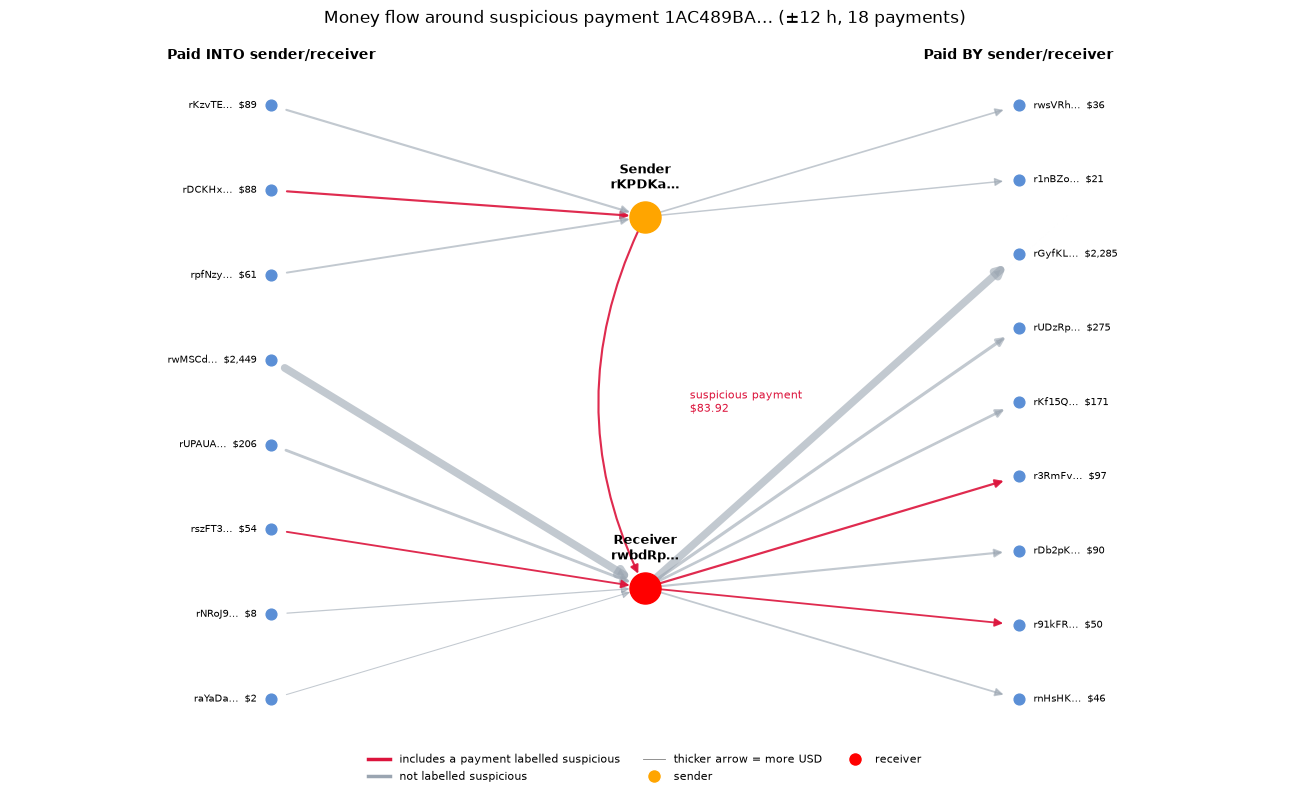

Sender Fan-out (distinct receivers): 3
Receiver Fan-in (distinct senders): 6
Investigating non-suspicious transaction: E7CAB61BBDAC502147EF393C7EA93A2A937DA3F01623E2F5AFD1399C17929AAF


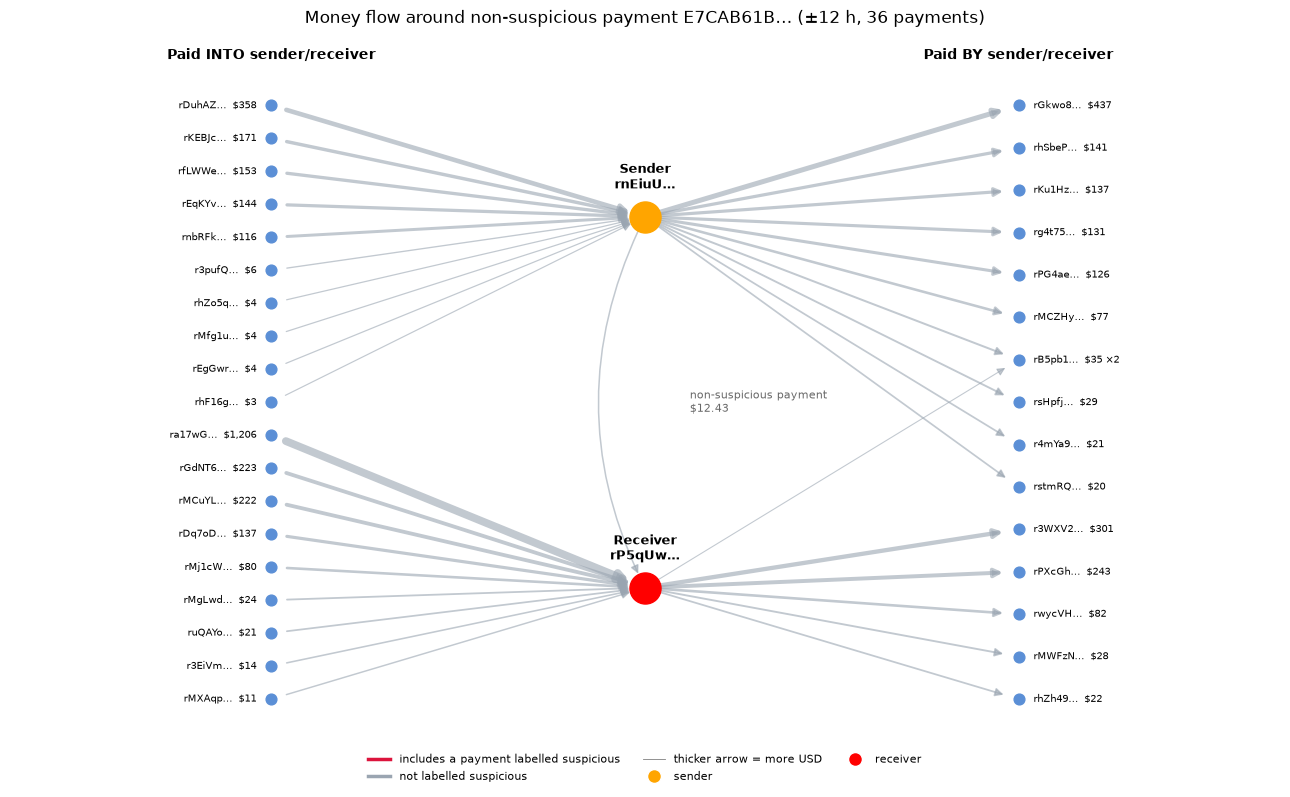

Sender Fan-out (distinct receivers): 11
Receiver Fan-in (distinct senders): 10


In [7]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# 1. Lists of suspicious and non-suspicious transaction hashes
suspicious_hashes = train[train['is_suspicious'] == 1]['TRANSACTION_HASH'].unique()
legit_hashes = train[train['is_suspicious'] == 0]['TRANSACTION_HASH'].unique()


def plot_flow(target_hash, kind):
    """Plot all payments to/from a transaction's sender and receiver within +/- 12 hours."""
    print(f"Investigating {kind} transaction: {target_hash}")

    # 3. Find the primary sender and receiver for this transaction
    target_tx = train[train['TRANSACTION_HASH'] == target_hash].iloc[0]
    suspect_sender = target_tx['FROM_ADDRESS']
    suspect_receiver = target_tx['TO_ADDRESS']

    # 4. Pull all activity involving these accounts within a time window (e.g., +/- 12 hours)
    time_window = 12 * 3600
    t_mid = target_tx['TIMESTAMP']
    window_mask = (train['TIMESTAMP'] >= t_mid - time_window) & (train['TIMESTAMP'] <= t_mid + time_window)

    # Get all edges connected to our suspects
    related_activity = train[
        window_mask &
        ((train['FROM_ADDRESS'] == suspect_sender) | (train['TO_ADDRESS'] == suspect_receiver) |
         (train['FROM_ADDRESS'] == suspect_receiver) | (train['TO_ADDRESS'] == suspect_sender))
    ]

    # 5. Build the Directed Graph: one edge per account pair, with total USD,
    # number of payments and whether any of them is labelled suspicious
    edges = (related_activity
             .groupby(['FROM_ADDRESS', 'TO_ADDRESS'])
             .agg(usd=('VALUE', 'sum'), n=('VALUE', 'size'), suspicious=('is_suspicious', 'max'))
             .reset_index())
    G = nx.DiGraph()
    for e in edges.itertuples():
        G.add_edge(e.FROM_ADDRESS, e.TO_ADDRESS, weight=e.usd, n=e.n, suspicious=bool(e.suspicious))

    # 6. Lay it out as a flow, left to right: payers -> suspects -> payees.
    # The suspect sender sits above the suspect receiver, so the flagged payment
    # runs down the middle. Counterparties are grouped by which suspect they deal with.
    suspects = [suspect_sender, suspect_receiver]
    pos = {suspect_sender: (0, 1), suspect_receiver: (0, -1)}
    payers = {'sender': [], 'receiver': []}
    payees = {'sender': [], 'receiver': []}
    for node in G.nodes:
        if node in suspects:
            continue
        pays_in = [s for s in suspects if G.has_edge(node, s)]
        paid_by = [s for s in suspects if G.has_edge(s, node)]
        if pays_in:
            payers['sender' if pays_in[0] == suspect_sender else 'receiver'].append(node)
        else:
            payees['sender' if paid_by[0] == suspect_sender else 'receiver'].append(node)


    def column(groups, x):
        """Stack the sender's counterparties on top, the receiver's below, biggest flows first."""
        nodes = []
        for key in ('sender', 'receiver'):
            nodes += sorted(groups[key], key=lambda a: -sum(d['weight'] for *_, d in G.edges(a, data=True))
                            - sum(d['weight'] for *_, d in G.in_edges(a, data=True)))
        ys = np.linspace(1.6, -1.6, len(nodes)) if len(nodes) > 1 else [0]
        for node, y in zip(nodes, ys):
            pos[node] = (x, y)
        return nodes


    left = column(payers, -1)
    right = column(payees, 1)

    fig, ax = plt.subplots(figsize=(13, max(8, 0.32 * max(len(left), len(right)))))
    max_usd = max(d['weight'] for *_, d in G.edges(data=True))
    for u, v, d in G.edges(data=True):
        is_target = (u, v) == (suspect_sender, suspect_receiver)
        nx.draw_networkx_edges(
            G, pos, edgelist=[(u, v)], ax=ax,
            width=0.6 + 5 * np.sqrt(d['weight'] / max_usd),
            edge_color='crimson' if d['suspicious'] else '#9aa5b1',
            alpha=0.9 if d['suspicious'] else 0.6,
            arrowsize=12, node_size=500 if u in suspects or v in suspects else 60,
            connectionstyle='arc3,rad=0.25' if is_target else 'arc3,rad=0.0',
        )

    others = [n for n in G.nodes if n not in suspects]
    nx.draw_networkx_nodes(G, pos, nodelist=others, node_color='#5b8fd6', node_size=60, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=[suspect_sender], node_color='orange', node_size=500, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=[suspect_receiver], node_color='red', node_size=500, ax=ax)


    def short(address):
        return f"{address[:6]}…"


    # Label each counterparty with its total USD and number of payments
    for node in others:
        x, y = pos[node]
        flows = list(G.out_edges(node, data=True)) + list(G.in_edges(node, data=True))
        usd, n = sum(d['weight'] for *_, d in flows), sum(d['n'] for *_, d in flows)
        text = f"{short(node)}  ${usd:,.0f}" + (f" ×{n}" if n > 1 else "")
        ax.text(x - 0.04 if x < 0 else x + 0.04, y, text, fontsize=7,
                ha='right' if x < 0 else 'left', va='center')

    for node, name in [(suspect_sender, 'Sender'), (suspect_receiver, 'Receiver')]:
        x, y = pos[node]
        ax.text(x, y + 0.13, f"{name}\n{short(node)}", ha='center', va='bottom', fontsize=9, fontweight='bold')
    ax.text(0.12, 0, f"{kind} payment\n${target_tx['VALUE']:,.2f}", fontsize=8,
            color='crimson' if target_tx['is_suspicious'] else 'dimgray', va='center')

    ax.text(-1, 1.85, 'Paid INTO sender/receiver', ha='center', fontsize=10, fontweight='bold')
    ax.text(1, 1.85, 'Paid BY sender/receiver', ha='center', fontsize=10, fontweight='bold')
    ax.legend(handles=[
        Line2D([], [], color='crimson', lw=2.5, label='includes a payment labelled suspicious'),
        Line2D([], [], color='#9aa5b1', lw=2.5, label='not labelled suspicious'),
        Line2D([], [], color='grey', lw=0.6, label='thicker arrow = more USD'),
        Line2D([], [], marker='o', color='w', markerfacecolor='orange', markersize=10, label='sender'),
        Line2D([], [], marker='o', color='w', markerfacecolor='red', markersize=10, label='receiver'),
    ], loc='lower center', bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=8, frameon=False)
    ax.set_xlim(-1.7, 1.7)
    ax.set_ylim(-1.8, 2.0)
    ax.axis('off')
    ax.set_title(f"Money flow around {kind} payment {target_hash[:8]}… "
                 f"(±{time_window // 3600} h, {len(related_activity)} payments)", fontsize=12)
    plt.tight_layout()
    plt.show()

    # 7. Print basic typology stats to match the training presentation
    print(f"Sender Fan-out (distinct receivers): {related_activity[related_activity['FROM_ADDRESS'] == suspect_sender]['TO_ADDRESS'].nunique()}")
    print(f"Receiver Fan-in (distinct senders): {related_activity[related_activity['TO_ADDRESS'] == suspect_receiver]['FROM_ADDRESS'].nunique()}")


# 2. Pick one of each to compare (change the numbers to look at others)
SUSPICIOUS_INDEX = 1
LEGIT_INDEX = 3
plot_flow(suspicious_hashes[SUSPICIOUS_INDEX], "suspicious")
plot_flow(legit_hashes[LEGIT_INDEX], "non-suspicious")